# Chapter 17

Python version of the R code for Chapter 17 of *In All Likelihood* (Pawitan, 2001).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import optimize, special

from helpers import scan, qqnorm, coef_table, dbinorm, num_hessian

## Example 17.6 (`EX17-6A.R`)

Standard logistic regression
              Estimate  Std. Error  value  Pr(>|value|)
(Intercept)      -0.56        0.13  -4.43          0.00
seed              0.15        0.22   0.65          0.51
extract           1.32        0.18   7.43          0.00
seed:extract     -0.78        0.31  -2.54          0.01


Estimate= [-0.55  0.1   1.34 -0.81  0.24]
SE's = [0.167 0.278 0.237 0.385 0.11 ]


[-1.17140691e+00 -1.10665851e+00 -9.36678576e-01 -7.02569256e-01
 -4.54335465e-01 -2.36323992e-01 -7.94136974e-02  0.00000000e+00
 -2.85223553e-03 -8.50237526e-02 -2.39262074e-01 -4.56445355e-01
 -7.27120174e-01 -1.04238145e+00 -1.39431948e+00 -1.77618658e+00
 -2.18237135e+00 -2.60823492e+00 -3.04983689e+00 -3.50344750e+00]


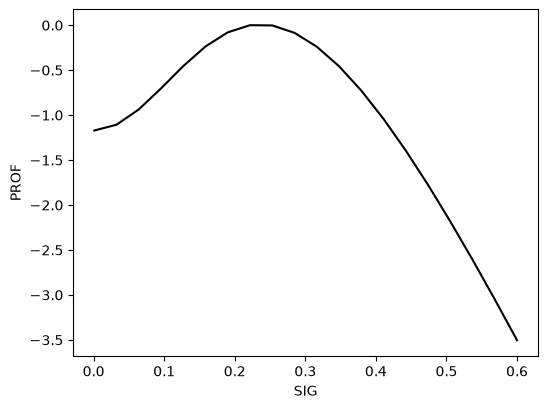

In [2]:
x = scan("seed.dat").reshape(-1, 2)
y = x[:, 0]  # number of successes
n = x[:, 1]

seed = np.repeat([0, 1], [11, 10])
extract = np.repeat([0, 1, 0, 1], [5, 6, 5, 5])

N = len(y)
X = np.zeros((N, 4))
X[:, 0] = 1
X[:, 1] = seed
X[:, 2] = extract
X[:, 3] = seed * extract

reg = sm.GLM(np.column_stack([y, n - y]), X, family=sm.families.Binomial()).fit()
print("Standard logistic regression")
print(coef_table(reg, ["(Intercept)", "seed", "extract", "seed:extract"]).round(2))


# ...........  GLMM
# ............  exact computation, using the binomial-normal marginal

# (In the R code these functions lack a final return value, so they return
# NULL; here they return the minus log-likelihood that they compute.)
def ELIKE0(beta, sig):
    """Exact minus log-likelihood."""
    if sig <= 0:
        return np.inf
    p = special.expit(X @ beta)
    return -sum(np.log(dbinorm(y[i], n[i], p[i], sig)) for i in range(N))


def ELIKE(param):
    return ELIKE0(param[:4], param[4])


beta0 = np.array([-.56, .15, 1.32, -.78])  # starting value from glm
opts = {"maxiter": 20000, "maxfev": 20000, "xatol": 1e-7, "fatol": 1e-9}
a = optimize.minimize(ELIKE, np.append(beta0, 0.05), method="Nelder-Mead", options=opts)

print("Estimate=", np.round(a.x, 2))
varmat = np.linalg.inv(num_hessian(ELIKE, a.x))
se = np.sqrt(np.diag(varmat))
print("SE's =", np.round(se, 3))

# computing profile likelihood for sigma
beta0 = a.x[:4]  # MLE for starting value
SIG = np.linspace(.001, .6, 20)

PROF = np.array([optimize.minimize(ELIKE0, beta0, args=(sig,), method="Nelder-Mead",
                                   options=opts).fun
                 for sig in SIG])
PROF = PROF.min() - PROF
print(PROF)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(SIG, PROF, "k-")
ax.set_xlabel("SIG")
ax.set_ylabel("PROF")
plt.show()

## Example 17.6, Figure 17.3 (`EX17-6B.R`)

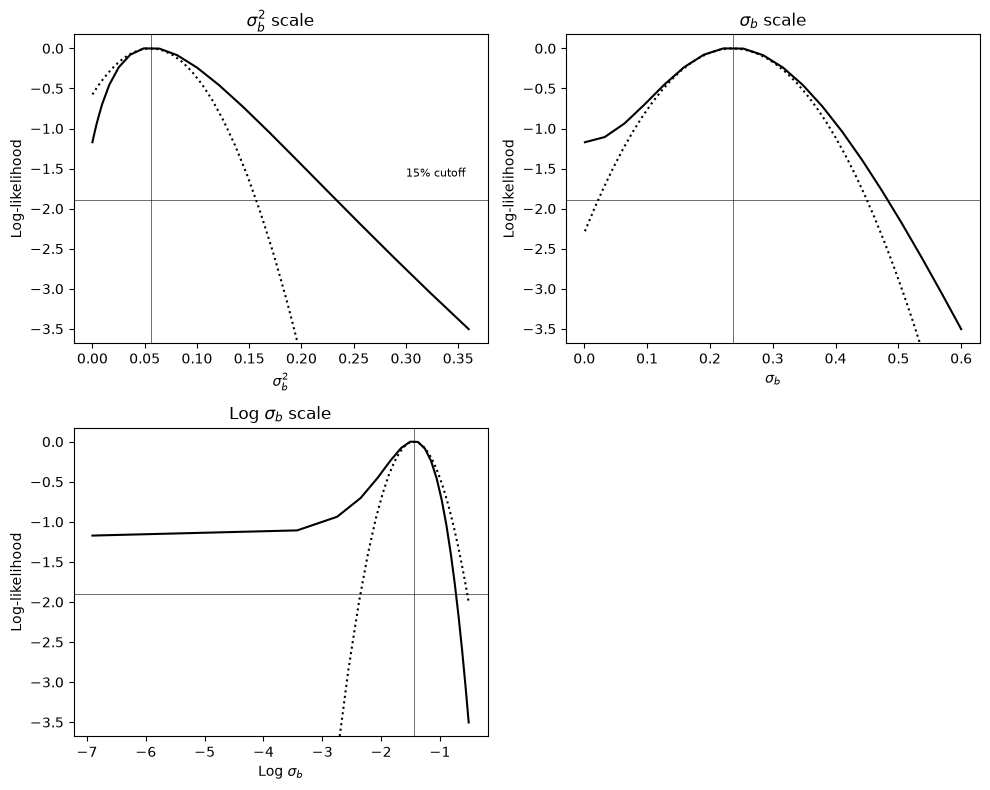

In [3]:
# .........................  profile likelihood from EX17-6A.R
SIG = np.linspace(.001, .6, 20)
PROF = np.array([-1.171406909, -1.106658507, -0.936678576, -0.702569256,
                 -0.454335465, -0.236323992, -0.079413698, 0.000000000,
                 -0.002852236, -0.085023753, -0.239262074, -0.456445355,
                 -0.727120174, -1.042381450, -1.394319476, -1.776186584,
                 -2.182371351, -2.608234921, -3.049836886, -3.503447502])

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

ax = axes[0]
ax.plot(SIG ** 2, PROF, "k-")
ax.axvline(0.236 ** 2, color="k", lw=0.4)
ax.axhline(np.log(.15), color="k", lw=0.4)
sig = np.linspace(0.001, .6, 40)
se = (2 * 0.236) * 0.11
lnorm = -1 / 2 / se ** 2 * (sig ** 2 - 0.236 ** 2) ** 2
lims = ax.get_xlim(), ax.get_ylim()  # R fixes the axes from the first plot
ax.plot(sig ** 2, lnorm, "k:", lw=1.5)
ax.set_xlim(lims[0])
ax.set_ylim(lims[1])
ax.text(.3, -1.6, "15% cutoff", fontsize=8)
ax.set_xlabel(r"$\sigma_b^2$")
ax.set_ylabel("Log-likelihood")
ax.set_title(r"$\sigma_b^2$ scale")

ax = axes[1]
ax.plot(SIG, PROF, "k-")
ax.axvline(0.236, color="k", lw=0.4)
ax.axhline(np.log(.15), color="k", lw=0.4)
se = 0.11
lnorm = -1 / 2 / se ** 2 * (sig - 0.236) ** 2
lims = ax.get_xlim(), ax.get_ylim()
ax.plot(sig, lnorm, "k:", lw=1.5)
ax.set_xlim(lims[0])
ax.set_ylim(lims[1])
ax.set_xlabel(r"$\sigma_b$")
ax.set_ylabel("Log-likelihood")
ax.set_title(r"$\sigma_b$ scale")

ax = axes[2]
ax.plot(np.log(SIG), PROF, "k-")
ax.axvline(np.log(0.236), color="k", lw=0.4)
ax.axhline(np.log(.15), color="k", lw=0.4)
se = 1 / 0.236 * 0.11
lnorm = -1 / 2 / se ** 2 * (np.log(sig) - np.log(0.236)) ** 2
lims = ax.get_xlim(), ax.get_ylim()
ax.plot(np.log(sig), lnorm, "k:", lw=1.5)
ax.set_xlim(lims[0])
ax.set_ylim(lims[1])
ax.set_xlabel(r"Log $\sigma_b$")
ax.set_ylabel("Log-likelihood")
ax.set_title(r"Log $\sigma_b$ scale")

axes[3].set_visible(False)
fig.tight_layout()
plt.show()

## Section 17.6: one-way random effects (`SEC17-6A.R`)

Fears et al data.

In [4]:
x = scan("random.dat").reshape(-1, 5)
x = 10 * np.log10(x)
q = 5
n = 16

y = x.ravel(order="F")  # data vector


def Zb(n, b):
    """Zb, without forming Z explicitly."""
    return np.repeat(b, n)


# initial estimates
xm = x.mean(axis=0)
xvar = x.var(axis=0, ddof=1)
s2 = xvar.mean()
s2b = np.var(xm, ddof=1)
lam = s2 / s2b

# iterating to estimate all parameters:
for i in range(1, 6):
    mu = y.mean()
    b = n * (xm - mu) / (n + lam)
    err = y - mu - Zb(n, b)
    df = q * n / (n + lam)
    s2 = np.sum(err ** 2) / (q * n - df)
    s2b = np.mean(b ** 2) + 1 / (n / s2 + 1 / s2b)
    lam = s2 / s2b
    print(i, np.round(np.concatenate([[mu], b, [s2b, s2]]), 4))

1 [14.1751 -0.623   0.2691  1.4433 -1.9199  0.8304  1.4039  0.3254]
2 [14.1751 -0.6211  0.2683  1.439  -1.9142  0.828   1.3957  0.3254]
3 [14.1751 -0.6211  0.2683  1.4389 -1.914   0.8279  1.3955  0.3254]
4 [14.1751 -0.6211  0.2683  1.4389 -1.914   0.8279  1.3955  0.3254]
5 [14.1751 -0.6211  0.2683  1.4389 -1.914   0.8279  1.3955  0.3254]


## Section 17.6: sleeping dog example (`SEC17-6B.R`)

0 [ 1.3311274e+03  4.2415903e+03  4.3875000e+02  1.0465790e+02
 -3.0026300e+01  1.2789500e+01  3.1380000e-01]
1 [ 1.7377005e+03  3.8577734e+03  4.3875000e+02  1.0465790e+02
 -3.0026300e+01  1.2789500e+01  4.5040000e-01]
2 [ 1.7474152e+03  3.6387353e+03  4.3875000e+02  1.0465790e+02
 -3.0026300e+01  1.2789500e+01  4.8020000e-01]
3 [ 1.7504964e+03  3.5937959e+03  4.3875000e+02  1.0465790e+02
 -3.0026300e+01  1.2789500e+01  4.8710000e-01]
4 [ 1.7512507e+03  3.5835765e+03  4.3875000e+02  1.0465790e+02
 -3.0026300e+01  1.2789500e+01  4.8870000e-01]
5 [ 1.7514289e+03  3.5812017e+03  4.3875000e+02  1.0465790e+02
 -3.0026300e+01  1.2789500e+01  4.8910000e-01]
6 [ 1.7514706e+03  3.5806471e+03  4.3875000e+02  1.0465790e+02
 -3.0026300e+01  1.2789500e+01  4.8910000e-01]
7 [ 1.7514804e+03  3.5805174e+03  4.3875000e+02  1.0465790e+02
 -3.0026300e+01  1.2789500e+01  4.8920000e-01]


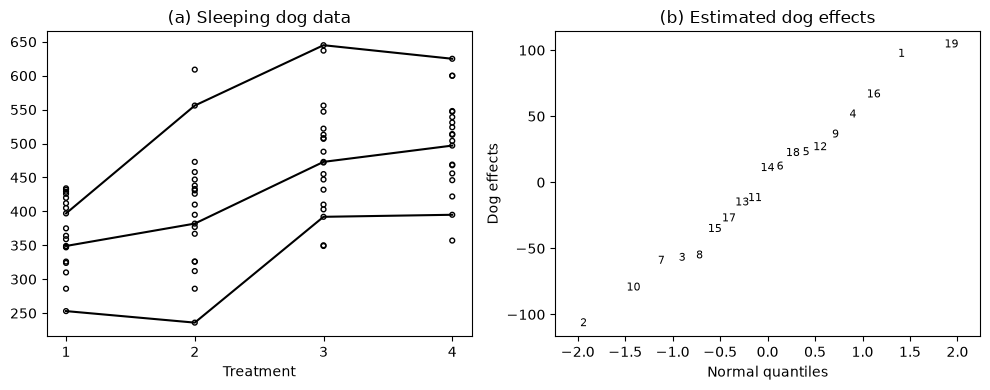

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.686
Model:                            OLS   Adj. R-squared:                  0.673
Method:                 Least Squares   F-statistic:                     52.43
Date:                Sat, 10 Oct 2026   Prob (F-statistic):           4.43e-18
Time:                        18:01:10   Log-Likelihood:                -382.06
No. Observations:                  76   AIC:                             772.1
Df Residuals:                      72   BIC:                             781.4
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
(Intercept)   438.7500      4.348    100.903      

In [5]:
x = scan("dog.dat", skip=2).reshape(-1, 4)
xm = x.mean(axis=1)
order = np.argsort(xm, kind="stable")  # order of the means
n = x.shape[0]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.scatter(np.repeat(np.arange(1, 5), n), x.ravel(order="F"), s=12, facecolors="none", edgecolors="k")
for i in [0, n // 2 - 1, n - 1]:
    ax.plot(np.arange(1, 5), x[order[i]], "k-")
ax.set_xticks([1, 2, 3, 4])
ax.set_xlabel("Treatment")
ax.set_title("(a) Sleeping dog data")

y = x.ravel(order="F")  # vectorized output
N = len(y)

# design matrix X: fixed effects
X = np.zeros((N, 4))
X[:, 0] = 1
X[:, 1] = np.repeat([-1, 1], [2 * n, 2 * n]) / 2  # effect of pressure with H
X[:, 2] = np.repeat([1, -1, 1, -1], n) / 2       # effect of high CO2
X[:, 3] = X[:, 1] * X[:, 2]
XX = X.T @ X


# operation with design matrix Z
def Z1y(y, n):
    """Z'y for any y: the sum over treatments for each dog."""
    return y.reshape(4, n).sum(axis=0)


def Zb(b):
    """Zb for any b."""
    return np.tile(b, 4)


# initial value
betahat = np.linalg.solve(XX, X.T @ y)
lam = 0
dog = np.tile(np.eye(n), (4, 1))
a = sm.OLS(y, np.column_stack([dog, X[:, 1], X[:, 2], X[:, 3]])).fit()

s2 = np.var(a.resid, ddof=1)
s2b = np.var(a.params[:n], ddof=1)
lam = s2 / s2b

i = 0
print(i, np.round(np.concatenate([[s2, s2b], betahat, [lam]]), 4))
olds2 = 100
olds2b = 100
# update
while abs(olds2 - s2) / s2 + abs(olds2b - s2b) / s2b > .0001:
    i += 1
    olds2 = s2
    olds2b = s2b
    ybeta = y - X @ betahat
    bhat = Z1y(ybeta, n) / (4 + lam)
    err = ybeta - Zb(bhat)
    df = n * np.sum(4 / (4 + lam))
    s2 = np.sum(err ** 2) / (N - df)
    s2b = 1 / n * (np.sum(bhat ** 2) + s2 * n * np.sum(1 / (4 + lam)))
    lam = s2 / s2b
    yb = y - Zb(bhat)
    betahat = np.linalg.solve(XX, X.T @ yb)
    print(i, np.round(np.concatenate([[s2, s2b], betahat, [lam]]), 4))

ax = axes[1]
qb, sb = qqnorm(bhat)
for k in range(n):
    ax.text(qb[k], sb[k], str(k + 1), fontsize=8, ha="center", va="center")
ax.set_xlim(qb.min() - .3, qb.max() + .3)
ax.set_ylim(sb.min() - 10, sb.max() + 10)
ax.set_xlabel("Normal quantiles")
ax.set_ylabel("Dog effects")
ax.set_title("(b) Estimated dog effects")
fig.tight_layout()
plt.show()

breg = sm.OLS(yb, X).fit()
print(breg.summary(xname=["(Intercept)", "X2", "X3", "X2:X3"]))

# ........... for comparisons:
# if assume fixed dog effects:
print("Assuming fixed dog effects")
print(coef_table(a).iloc[n:n + 3].set_axis(["X2", "X3", "X2:X3"]))

# testing interaction only:
inter = (x[:, 0] + x[:, 3]) - (x[:, 1] + x[:, 2])  # note: formula on page 452 is wrong
print(inter)
print("estimated interaction= ", inter.mean(), "(se = ", np.std(inter, ddof=1) / np.sqrt(19), ")")

# hydrogen effect:
hydro = (x[:, 2] + x[:, 3]) / 2 - (x[:, 0] + x[:, 1]) / 2
print(hydro)
print("estimated hydrogen effect= ", hydro.mean(), "(se = ", np.std(hydro, ddof=1) / np.sqrt(19), ")")

# CO2 effect:
CO2 = (x[:, 1] + x[:, 3]) / 2 - (x[:, 0] + x[:, 2]) / 2
print(CO2)
print("estimated CO2 effect= ", CO2.mean(), "(se = ", np.std(CO2, ddof=1) / np.sqrt(19), ")")

## Section 17.7: growth curve analysis (`SEC17-7.R`)

0 s0= 6.264802631578945 s1= 1.3582357894736832 se= 0.12896666666666667
1 s0= 5.938170780835549 s1= 1.1216497428787215 se= 0.19056679984672953
2 s0= 5.905168830120373 s1= 1.0068201092839626 se= 0.19340943045866624
3 s0= 5.9035819319133225 s1= 0.9762102112376095 se= 0.19478098255373932
4 s0= 5.903004485484473 s1= 0.9662821590035945 se= 0.19528746800611477
5 s0= 5.902789778970227 s1= 0.9628774024974665 se= 0.19546829146006092
6 s0= 5.902712844750933 s1= 0.9616881069925869 se= 0.1955323155149409
7 s0= 5.90268557444246 s1= 0.9612700452121535 se= 0.19555492735588723
8 s0= 5.9026759397591535 s1= 0.961122762562829 se= 0.19556290662601225
9 s0= 5.90267253946044 s1= 0.9610708347034171 se= 0.195565721533181
10 s0= 5.902671339861214 s1= 0.9610525213346899 se= 0.19556671446801158


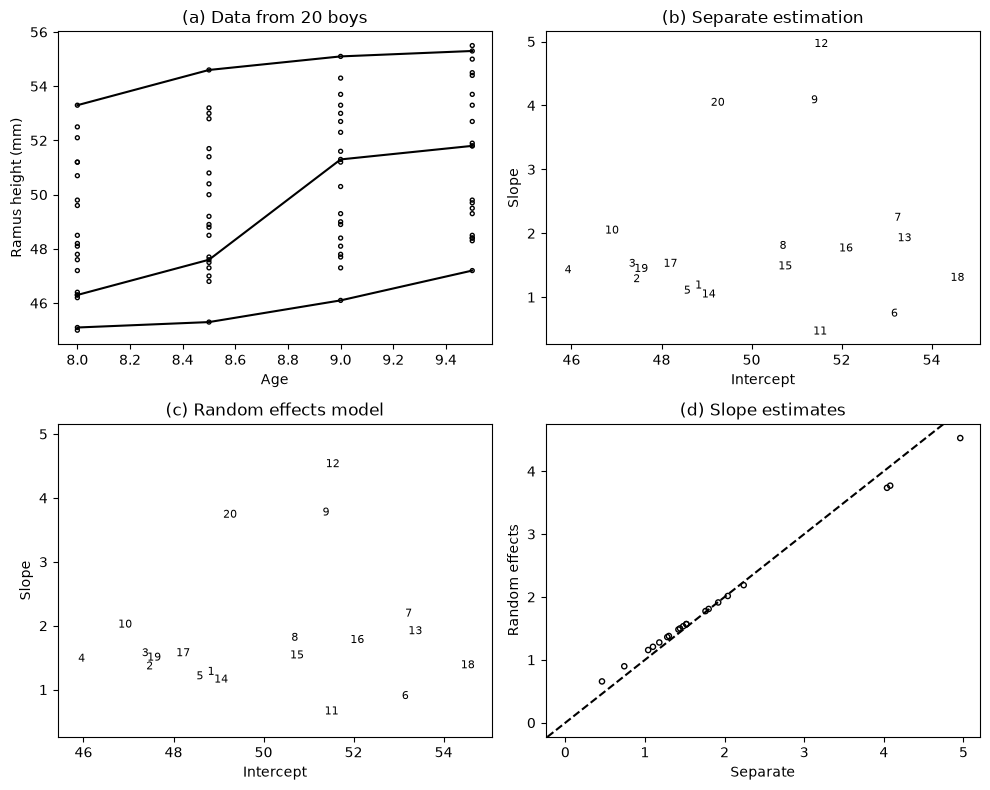

betahat= [50.075  1.866]
std-err= [0.5455 0.2364]

.... ignoring repeated measures:
             Estimate  Std. Error       value   Pr(>|value|)
(Intercept)    50.075    0.287596  174.115505  8.277352e-103
X[, 2]          1.866    0.514468    3.627047   5.095928e-04

.... two-staged LS
betahat [50.0496  1.8616]
std err= [0.5563 0.2089]

covariance matrix with no assumption=
[[6.33   6.1891 5.777  5.5482]
 [6.1891 6.4493 6.1534 5.9234]
 [5.777  6.1534 6.918  6.9463]
 [5.5482 5.9234 6.9463 7.4647]]
covariance matrix using random effects=
[[6.6388 6.0829 5.7225 5.3621]
 [6.0829 6.1583 5.8426 5.7225]
 [5.7225 5.8426 6.1583 6.0829]
 [5.3621 5.7225 6.0829 6.6388]]


In [6]:
x = scan("ramus.dat").reshape(-1, 5)
x = x[:, 1:5]
xm = x.mean(axis=1)
order = np.argsort(xm, kind="stable")  # order of the means
n = x.shape[0]
age = 8 + .5 * np.arange(4)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

ax = axes[0]
ax.scatter(np.repeat(age, n), x.ravel(order="F"), s=8, facecolors="none", edgecolors="k")
for i in [0, n // 2 - 1, n - 1]:
    ax.plot(age, x[order[i]], "k-")
ax.set_xlabel("Age")
ax.set_ylabel("Ramus height (mm)")
ax.set_title("(a) Data from 20 boys")

# starting values: a separate straight line for each boy
slope = []
evar = []
for i in range(n):
    coef = np.polyfit(age - age.mean(), x[i], 1)[::-1]  # intercept, slope
    slope.append(coef)
    evar.append(np.var(x[i] - np.polyval(coef[::-1], age - age.mean()), ddof=1))
slope = np.array(slope)
evar = np.array(evar)
s0 = np.var(slope[:, 0], ddof=1)
s1 = np.var(slope[:, 1], ddof=1)
se = evar.mean()

# ................................................... fixed effects
ax = axes[1]
for i in range(n):
    ax.text(slope[i, 0], slope[i, 1], str(i + 1), fontsize=8, ha="center", va="center")
ax.set_xlim(slope[:, 0].min() - .5, slope[:, 0].max() + .5)
ax.set_ylim(slope[:, 1].min() - .2, slope[:, 1].max() + .2)
ax.set_xlabel("Intercept")
ax.set_ylabel("Slope")
ax.set_title("(b) Separate estimation")

# assume that random b0 and b1 are independent
#   which makes sense if age is centered.
age = age - age.mean()
y = x.ravel()  # vectorized data **** by individuals ****
ni = np.full(n, 4)
N = len(y)

# fixed effects:
X = np.column_stack([np.ones(N), np.tile(age, n)])
XX = X.T @ X


# ...........................   random effects operators
def Z0y(y, n):
    return y.reshape(n, -1).sum(axis=1)


def Z0b(b, ni):
    return np.repeat(b, ni)


def Z1y(age, y, n):
    return y.reshape(n, -1) @ age


def Z1b(age, b, ni):
    return np.tile(age, n) * np.repeat(b, ni)


# Z1'Z1 = diag[a_i], where a_i = sum(age^2)
age2 = np.sum(age ** 2)

# .............................   iterations:
beta = np.linalg.solve(XX, X.T @ y)
b0 = slope[:, 0] - beta[0]
rb0 = (slope[:, 0].min(), slope[:, 0].max())
rb1 = (slope[:, 1].min(), slope[:, 1].max())

# iterate
print(0, "s0=", s0, "s1=", s1, "se=", se)
for i in range(1, 11):
    # update b1
    yc = y - X @ beta - Z0b(b0, ni)
    lambda1 = se / s1
    b1 = Z1y(age, yc, n) / (age2 + lambda1)

    # update beta
    yc = y - Z0b(b0, ni) - Z1b(age, b1, ni)
    beta = np.linalg.solve(XX, X.T @ yc)

    # update b0
    yc = y - X @ beta - Z1b(age, b1, ni)
    lambda0 = se / s0
    b0 = Z0y(yc, n) / (ni + lambda0)

    # update: variance components
    err = y - X @ beta - Z0b(b0, ni) - Z1b(age, b1, ni)
    df0 = np.sum(ni / (ni + lambda0))
    df1 = n * age2 / (age2 + lambda1)
    se = np.sum(err ** 2) / (N - df0 - df1)
    s0 = 1 / n * (np.sum(b0 ** 2) + se * np.sum(1 / (ni + lambda0)))
    s1 = 1 / n * (np.sum(b1 ** 2) + se * np.sum(1 / (age2 + lambda1)))

    print(i, "s0=", s0, "s1=", s1, "se=", se)

ax = axes[2]
for k in range(n):
    ax.text(beta[0] + b0[k], beta[1] + b1[k], str(k + 1), fontsize=8, ha="center", va="center")
ax.set_xlim(rb0[0] - .5, rb0[1] + .5)
ax.set_ylim(rb1[0] - .2, rb1[1] + .2)
ax.set_xlabel("Intercept")
ax.set_ylabel("Slope")
ax.set_title("(c) Random effects model")

ax = axes[3]
ax.scatter(slope[:, 1], beta[1] + b1, s=14, facecolors="none", edgecolors="k")
ax.axline((0, 0), slope=1, color="k", ls="--")
ax.set_xlabel("Separate")
ax.set_ylabel("Random effects")
ax.set_title("(d) Slope estimates")
fig.tight_layout()
plt.show()

# standard error for the fixed effects: X S^{-1}(X-Z bx)
Xerr = []
for i in range(X.shape[1]):
    yc = X[:, i]
    b0 = Z0y(yc, n) / (ni + lambda0)
    b1 = Z1y(age, yc, n) / (age2 + lambda1)
    Xerr.append(yc - Z0b(b0, ni) - Z1b(age, b1, ni))
Xerr = np.column_stack(Xerr)
XVX = X.T @ Xerr / se
varmat = np.linalg.inv(XVX)
print("betahat=", np.round(beta, 4))
print("std-err=", np.round(np.sqrt(np.diag(varmat)), 4))
print()

# ........................   ignoring repeated measures:
reg = sm.OLS(y, X).fit()
print(".... ignoring repeated measures:")
print(coef_table(reg, ["(Intercept)", "X[, 2]"]))
print()

# ........................   comparison: two-staged LS
beta2 = np.linalg.solve(XX, X.T @ y)
err0 = (y - X @ beta2).reshape(-1, 4)
V = np.cov(err0, rowvar=False)
Vinv = np.linalg.inv(V)
XVX = n * X[:4].T @ Vinv @ X[:4]
XVy = sum(X[:4].T @ Vinv @ x[i] for i in range(n))
beta2 = np.linalg.solve(XVX, XVy)
var2 = np.linalg.inv(XVX)
print(".... two-staged LS")
print("betahat", np.round(beta2, 4))
print("std err=", np.round(np.sqrt(np.diag(var2)), 4))
print()

print("covariance matrix with no assumption=")
print(np.round(V, 4))

# covariance matrix of the repeated measures: using random effects:
Vran = np.diag(np.full(4, se)) + s0 + s1 * np.outer(age, age)
print("covariance matrix using random effects=")
print(np.round(Vran, 4))

## Example 17.11 (`EX17-11A.R`)

1 [-0.55  0.11  1.32 -0.79  0.24]
2 [-0.55  0.1   1.32 -0.8   0.24]
3 [-0.54  0.1   1.33 -0.8   0.24]
4 [-0.54  0.1   1.33 -0.8   0.24]
5 [-0.54  0.1   1.33 -0.81  0.24]
6 [-0.54  0.1   1.33 -0.81  0.24]
7 [-0.54  0.1   1.33 -0.81  0.24]
8 [-0.54  0.1   1.33 -0.81  0.23]
9 [-0.54  0.1   1.33 -0.81  0.23]
10 [-0.54  0.1   1.33 -0.81  0.23]


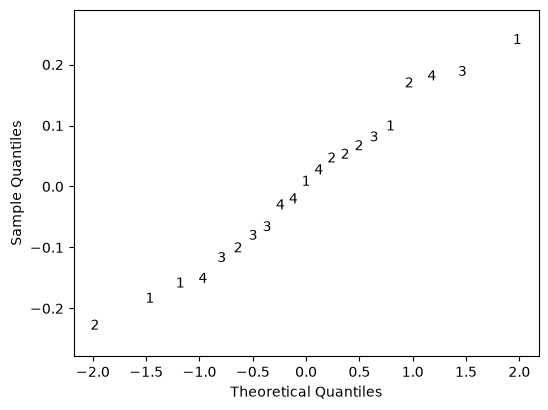

Std errors of betahat= [0.17 0.27 0.23 0.38]


In [7]:
x = scan("seed.dat").reshape(-1, 2)
y = x[:, 0]  # number of successes
n = x[:, 1]

seed = np.repeat([0, 1], [11, 10])
extract = np.repeat([0, 1, 0, 1], [5, 6, 5, 5])

N = len(y)
X = np.zeros((N, 4))
X[:, 0] = 1
X[:, 1] = seed
X[:, 2] = extract
X[:, 3] = seed * extract

reg = sm.GLM(np.column_stack([y, n - y]), X, family=sm.families.Binomial()).fit()

# starting values
beta = reg.params
b = 0
s2b = .24 ** 2


def Yfun(beta, b):
    """Working variate Y and weights for the IWLS step."""
    eta = X @ beta + b
    p = np.exp(eta) / (1 + np.exp(eta))
    err = (y - n * p) / (n * p * (1 - p))
    Y = eta + err
    wt = n * p * (1 - p)
    return Y, wt


LSIG = []  # log-likelihood of s2b
SIG = []
for i in range(1, 11):
    # step 1
    Y, wt = Yfun(beta, b)
    b = wt * (Y - X @ beta) / (wt + 1 / s2b)
    # step 2
    XWX = X.T @ (wt[:, None] * X)
    XWY = X.T @ (wt * (Y - b))
    beta = np.linalg.solve(XWX, XWY)
    # step 3
    s2b = np.mean(b ** 2) + np.mean(1 / (wt + 1 / s2b))

    # profile likelihood
    lsig = (-1 / 2 * np.sum(np.log(wt)) + np.sum(wt * (Y - X @ beta - b) ** 2) / 2
            + N / 2 * np.log(s2b) + 1 / 2 / s2b * np.sum(b ** 2) + 1 / 2 * np.sum(np.log(wt + 1 / s2b)))
    LSIG.append(lsig)
    SIG.append(np.sqrt(s2b))
    print(i, np.round(np.append(beta, np.sqrt(s2b)), 2))

# normality of random effects
nn = [5, 6, 5, 5]
group = np.repeat([1, 2, 3, 4], nn)
varb = [np.var(b[group == g], ddof=1) for g in range(1, 5)]
qb, sb = qqnorm(b)
fig, ax = plt.subplots(figsize=(6, 4.5))
for k in range(N):
    ax.text(qb[k], sb[k], str(group[k]), ha="center", va="center")
ax.set_xlim(qb.min() - .2, qb.max() + .2)
ax.set_ylim(sb.min() - .05, sb.max() + .05)
ax.set_xlabel("Theoretical Quantiles")
ax.set_ylabel("Sample Quantiles")
plt.show()

# getting standard errors:
V = 1 / wt + s2b
XVX = X.T @ (1 / V[:, None] * X)
vars_ = np.diag(np.linalg.inv(XVX))
print("Std errors of betahat=", np.round(np.sqrt(vars_), 2))

## `EX17-11B.R`

This script is headed "Exercise 18.11: Figure 17.4".

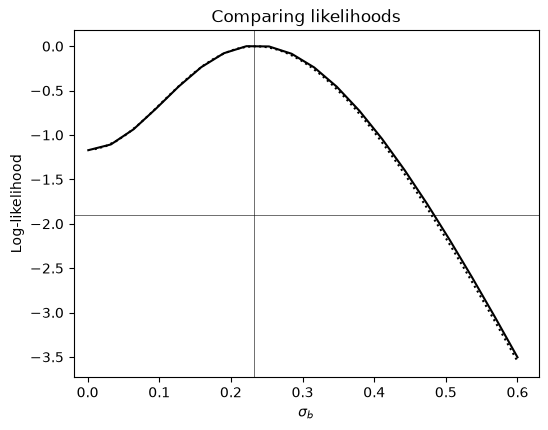

In [8]:
x = scan("seed.dat").reshape(-1, 2)
y = x[:, 0]  # success
n = x[:, 1]

seed = np.repeat([0, 1], [11, 10])
extract = np.repeat([0, 1, 0, 1], [5, 6, 5, 5])

N = len(y)
X = np.zeros((N, 4))
X[:, 0] = 1
X[:, 1] = seed
X[:, 2] = extract
X[:, 3] = seed * extract

reg = sm.GLM(np.column_stack([y, n - y]), X, family=sm.families.Binomial()).fit()


def Yfun(beta, b):
    """Working variate Y and weights for the IWLS step."""
    eta = X @ beta + b
    p = np.exp(eta) / (1 + np.exp(eta))
    err = (y - n * p) / (n * p * (1 - p))
    Y = eta + err
    wt = n * p * (1 - p)
    return Y, wt


LSIG = []  # log-likelihood of s2b
LSIG2 = []
SIG = np.linspace(.01, .6, 40)
beta = reg.params  # starting value for iteration
b = 0

for s2b in SIG ** 2:
    nrep = 20 if s2b == SIG[0] ** 2 else 5
    for i in range(nrep):
        # step 1
        Y, wt = Yfun(beta, b)
        b = wt * (Y - X @ beta) / (wt + 1 / s2b)
        # step 2
        XWX = X.T @ (wt[:, None] * X)
        XWY = X.T @ (wt * (Y - b))
        beta = np.linalg.solve(XWX, XWY)
    # profile likelihood
    lsig = (1 / 2 * np.sum(np.log(wt)) - 1 / 2 * np.sum(wt * (Y - X @ beta - b) ** 2)
            - N / 2 * np.log(s2b) - 1 / 2 / s2b * np.sum(b ** 2) - 1 / 2 * np.sum(np.log(wt + 1 / s2b)))
    LSIG2.append(lsig)  # quad-approx

    eta = X @ beta + b
    p = np.exp(eta) / (1 + np.exp(eta))
    lsig = (np.sum(y * np.log(p) + (n - y) * np.log(1 - p))
            - N / 2 * np.log(s2b) - 1 / 2 / s2b * np.sum(b ** 2) - 1 / 2 * np.sum(np.log(wt + 1 / s2b)))
    LSIG.append(lsig)  # exp-family likelihood

# ........................  plot of log-likelihood for sig
LSIG = np.array(LSIG)
LSIG = LSIG - LSIG.max()
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(SIG, LSIG, "k:", lw=1.5)
# ax.plot(SIG, LSIG2, "k--")
ax.axvline(np.sqrt(.0541), color="k", lw=0.4)
ax.axhline(np.log(.15), color="k", lw=0.4)
lims = ax.get_xlim(), ax.get_ylim()  # R fixes the axes from the first plot

# ..................... exact profile likelihood from EX17-6A.R
ESIG = np.linspace(.001, .6, 20)
EPROF = np.array([-1.171406909, -1.106658507, -0.936678576, -0.702569256,
                  -0.454335465, -0.236323992, -0.079413698, 0.000000000,
                  -0.002852236, -0.085023753, -0.239262074, -0.456445355,
                  -0.727120174, -1.042381450, -1.394319476, -1.776186584,
                  -2.182371351, -2.608234921, -3.049836886, -3.503447502])
ax.plot(ESIG, EPROF, "k-")
ax.set_xlim(lims[0])
ax.set_ylim(lims[1])
ax.set_xlabel(r"$\sigma_b$")
ax.set_ylabel("Log-likelihood")
ax.set_title("Comparing likelihoods")
plt.show()